# 8 · TF-IDF + cosine

**Owner:** Member 2 · **Branch:** `dev-tfidf` · **Code:** `src/discovery/rank/tfidf.py` → class `TfidfRanker` · **Writes to:** `eval/results/tfidf.json`

**What it means:** Each repository becomes a vector with one number per word: how often the word appears in it (TF), times how rare the word is across all repositories (IDF). The query becomes a vector the same way, and repositories are ranked by the cosine of the angle between the two vectors.

**Key idea:** Rare words count more: "nestjs" says more about a repository than "app". Cosine compares direction, not length, so a long README doesn't win just by being long. It is the classic baseline BM25 should beat (hypothesis H1).

Full guide with starter code, and the Results sheet: [team plan](https://claude.ai/artifact/Rst8GHxAbeHavg4JS2RZV3) (tab 8 TF-IDF + cosine). Handoff and setup: `docs/handoff-methods.md`.

### Settings to try
| Setting | Values | Why |
|---|---|---|
| tf | raw count vs 1 + log(count) | Sublinear tf stops a word repeated 50 times from counting 50×. |
| idf | log((1 + N) / (1 + df)) + 1 | Smooth idf, as in scikit-learn. |
| field weights | README only vs name + topics repeated 3× | Words in the name and topics are stronger evidence than a word deep in the README. |
| min_df | 1, 2, 5 | Drop words that appear in fewer repositories (typos, ids). |

**Fixed:** our own implementation (numpy + scipy.sparse), checked against scikit-learn's TfidfVectorizer

### What we agreed (same for all five)
- **One tokenizer:** `tokenize()` from `discovery.preprocess.text`, for documents *and* queries. Never a private one.
- **One interface:** your class extends `SearchMethod` (`src/discovery/rank/base.py`): `fit(corpus)` → self, `search(query, k)` → `[{"doc_id": full_name, "score": float}]`, best first. `check_hits()` checks it.
- **Tune on the 5 development queries only** (`DEV`, replaced by the real ones in Phase 13). The 20 test queries are for the final number only.
- **Seed 42**, paths from `PATHS`, and don't edit the shared files (`rank/base.py`, `rank/devkit.py`, `preprocess/text.py`, `config/config.yaml`) on your branch: ask Member 6.
- Commit this notebook **with its outputs** on `dev-tfidf`. No data files in git.

## 1. Setup: load the corpus and the shared tokenizer

**Check:** it prints 8,223 repositories, and `node.js` and `c#` come out of `tokenize()` in one piece.

In [1]:
%load_ext autoreload
%autoreload 2

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from discovery.config import PATHS, SEED, set_seed
from discovery.preprocess.text import doc_text, tokenize      # the ONE shared tokenizer (Phase 6)
from discovery.rank.base import check_hits
from discovery.rank.devkit import DEV, load_corpus, measure, save_results, show_top
from discovery.rank.tfidf import FIELDS, TfidfRanker, field_tokens

set_seed()
corpus = load_corpus()                                   # data/processed/corpus.parquet
ids = corpus["full_name"].tolist()                       # doc_id = full_name, "owner/name"
text = doc_text(corpus).tolist()                         # name + description + topics + README
print(f"{len(corpus):,} repositories |", tokenize("Built with Node.js and C#"))
print("development queries:", *DEV, sep="\n  ")

8,223 repositories | ['built', 'node.js', 'c#']
development queries:
  beginner inventory management system nestjs postgresql
  point of sale app with react
  school management system laravel
  hotel booking system spring boot
  simple chat application flutter firebase


## 2. Build: TF-IDF + cosine

One sparse row per repository. After scaling every row to length 1, the cosine between two vectors is just their dot product.

**Check:** it runs once on the whole corpus without errors. Write down how long it took: it goes in the sheet.

<details><summary>Starter code from the team plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
import numpy as np
from collections import Counter
from scipy import sparse

docs = [tokenize(t) for t in text]
vocab = {w: j for j, w in enumerate(sorted({w for d in docs for w in d}))}
N = len(docs)
rows, cols, vals = [], [], []
for i, d in enumerate(docs):
    for w, c in Counter(d).items():
        rows.append(i); cols.append(vocab[w]); vals.append(1 + np.log(c))     # sublinear tf
tf = sparse.csr_matrix((vals, (rows, cols)), shape=(N, len(vocab)))
df = np.bincount(tf.indices, minlength=len(vocab))                             # repositories per word
idf = np.log((1 + N) / (1 + df)) + 1
X = tf.multiply(idf).tocsr()
X = sparse.diags(1 / np.sqrt(X.multiply(X).sum(1).A1 + 1e-12)) @ X               # unit length: cosine = dot
print(X.shape, f"{X.nnz / N:.0f} non-zero words per repository")
```
</details>

In [2]:
from collections import Counter

from scipy import sparse

t = time.perf_counter()
docs = [tokenize(x) for x in text]                   # the shared tokenizer, once for the whole corpus
print(f"tokenized in {time.perf_counter() - t:.1f} s")

t = time.perf_counter()
N = len(docs)
vocab = {w: j for j, w in enumerate(sorted({w for d in docs for w in d}))}
rows, cols, vals = [], [], []
for i, d in enumerate(docs):
    for w, c in Counter(d).items():
        rows.append(i); cols.append(vocab[w]); vals.append(1 + np.log(c))     # sublinear tf
tf = sparse.csr_matrix((vals, (rows, cols)), shape=(N, len(vocab)))
df = np.bincount(tf.indices, minlength=len(vocab))                             # repositories per word
idf = np.log((1 + N) / (1 + df)) + 1                                           # smooth idf, never below 1
X = tf.multiply(idf).tocsr()
X = sparse.diags(1 / np.sqrt(X.multiply(X).sum(1).A1 + 1e-12)) @ X               # unit length: cosine = dot
print(f"weighted and scaled in {time.perf_counter() - t:.1f} s")

dl = np.array([len(d) for d in docs])                # tokens per repository
print(f"{X.shape[0]:,} repositories x {X.shape[1]:,} words | {X.nnz / N:.0f} non-zero words per repository "
      f"| every row has length 1: {np.allclose(np.sqrt(X.multiply(X).sum(1).A1), 1)}")
print(f"average length {dl.mean():.0f} tokens (median {np.median(dl):.0f})")
print("idf:", {w: round(float(idf[vocab[w]]), 2) for w in ["nestjs", "postgresql", "inventory", "management", "app", "system"]},
      f"(range {idf.min():.2f} to {idf.max():.2f})")

tokenized in 10.0 s


weighted and scaled in 4.5 s
8,223 repositories x 148,623 words | 306 non-zero words per repository | every row has length 1: True
average length 692 tokens (median 361)
idf: {'nestjs': 3.9, 'postgresql': 2.77, 'inventory': 3.02, 'management': 1.72, 'app': 1.62, 'system': 1.54} (range 1.34 to 9.32)


## 3. Search: a free-text query in, a ranked list out

The query gets the same weights. One sparse matrix–vector product scores all repositories; keep the top k with a score above 0.

**Check:** the top 10 for `DEV[0]` look plausible when you read their names and descriptions.

<details><summary>Starter code from the team plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
def search(query, k=10):
    q = np.zeros(len(vocab))
    for w, c in Counter(tokenize(query)).items():
        if w in vocab:
            q[vocab[w]] = (1 + np.log(c)) * idf[vocab[w]]
    if not q.any():
        return []
    s = X @ (q / np.linalg.norm(q))                       # cosine with every repository at once
    top = np.argsort(-s)[:k]
    return [{"doc_id": ids[i], "score": float(s[i])} for i in top if s[i] > 0]

search(DEV[0])
```
</details>

In [3]:
def search(query, k=10):
    q = np.zeros(len(vocab))
    for w, c in Counter(tokenize(query)).items():
        if w in vocab:
            q[vocab[w]] = (1 + np.log(c)) * idf[vocab[w]]
    if not q.any():
        return []
    s = X @ (q / np.linalg.norm(q))                       # cosine with every repository at once
    top = np.argsort(-s, kind="stable")[:k]               # stable: ties keep corpus order
    return [{"doc_id": ids[i], "score": float(s[i])} for i in top if s[i] > 0]

print(DEV[0], "->", tokenize(DEV[0]))
pd.DataFrame(search(DEV[0])).merge(corpus[["full_name", "stars", "description"]], left_on="doc_id", right_on="full_name") \
  .drop(columns="full_name").assign(description=lambda d: d.description.str[:70]).round(3)

beginner inventory management system nestjs postgresql -> ['beginner', 'inventory', 'management', 'system', 'nestjs', 'postgresql']


,doc_id,score,stars,description
0,jmw5598/inventory-management-system,0.518,15,"Inventory management system using Angular 9, N..."
1,legionscript/inventory_management,0.347,34,Inventory Management project tutorial written ...
2,henriqueweiand/nestjs-auth-flow-blog-post,0.318,5,not specified
3,guruminion777/React-Inventory-Management-System,0.313,9,not specified
4,mhmamun6316/inventory_management_system,0.308,6,Inventory Management System with Point of Sale...
5,leandre000/ai-inventory,0.305,6,ai inventory management system
6,Mahade-Hasan-Forhad/inventory-management-system,0.299,5,"Inventory Management System using HTML, CSS, B..."
7,samisams1/Inventory-Management-React-Nest-Grap...,0.275,13,"Inventory Management System with React, TypeSc..."
8,jvoyugi/inventory,0.272,12,An inventory management system using Django we...
9,pedroreis07/hospital-management,0.271,8,Back-end Application - Developed with PostgreS...


## 4. Move it into `src/discovery/rank/tfidf.py` as `TfidfRanker`

The stub is already there with the right signature. Fill in `fit` and `search` (and `params`), then load it here with `discovery.rank.tfidf.TfidfRanker`: autoreload picks up your edits.

**Check:** `check_hits` passes below, and in a terminal `pytest tests/test_methods.py -k tfidf` passes (it was skipped until now).

<details><summary>The search method, as in the plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
    def search(self, query, k=10):
        ...  # the function above, using self.vocab, self.idf, self.X, self.ids
```
</details>

In [4]:
t = time.perf_counter()
fields = field_tokens(corpus)                        # name, description, topics, README, each tokenized once
print(f"fields tokenized in {time.perf_counter() - t:.1f} s (reused for every setting in step 7)")
assert all([w for f in FIELDS for w in fields[f][i]] == docs[i] for i in range(N))
print("the four fields one after the other = exactly the doc_text tokens of step 2, on all", N, "repositories")

# the setting of steps 2-3 (the starter code: sublinear tf); step 7 picks the setting the class uses by default
method = TfidfRanker(sublinear_tf=True).fit(corpus, tokens=fields)   # tokens: skip tokenizing again
check_hits(method.search(DEV[0], 10), k=10)

# the class gives exactly the notebook function's ranking and scores
for q in DEV:
    a, b = search(q), method.search(q)
    assert [h["doc_id"] for h in a] == [h["doc_id"] for h in b], q
    assert np.allclose([h["score"] for h in a], [h["score"] for h in b]), q
print("class == notebook function on all 5 development queries")
method.params()

fields tokenized in 13.3 s (reused for every setting in step 7)
the four fields one after the other = exactly the doc_text tokens of step 2, on all 8223 repositories


class == notebook function on all 5 development queries


{'tf': 'sublinear',
 'idf': 'smooth',
 'min_df': 1,
 'field_weights': {'name': 1, 'description': 1, 'topics': 1, 'readme': 1}}

## 5. Compare with a reference: scikit-learn

With the same tokenizer and settings, `TfidfVectorizer` should give almost the same ranking. Small differences can come from ties.

**Check:** 9 or 10 of 10 the same on every development query. If not, compare idf first: print both for one word.

<details><summary>The check, as in the plan (open it if you are stuck; adapt it, don't just paste)</summary>

```python
from sklearn.feature_extraction.text import TfidfVectorizer

ref = TfidfVectorizer(analyzer=tokenize, sublinear_tf=True).fit(text)
R = ref.transform(text)
for q in DEV:
    ours = [h["doc_id"] for h in search(q)]
    s = (R @ ref.transform([q]).T).toarray().ravel()
    theirs = [ids[i] for i in np.argsort(-s)[:10]]
    print(f"{len(set(ours) & set(theirs)):2d}/10 the same | {q}")
```
</details>

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

# analyzer: the docs are already tokenized with tokenize(), the same as analyzer=tokenize on the raw text
ref = TfidfVectorizer(analyzer=lambda d: d, sublinear_tf=True).fit(docs)
R = ref.transform(docs)
perm = [ref.vocabulary_[w] for w in method.vocab]   # scikit-learn sorts its words: put its columns in our order
print(f"same words: {set(method.vocab) == set(ref.vocabulary_)} | largest difference between the two matrices: "
      f"{abs(method.X - R[:, perm]).max():.1e}")
for w in ["nestjs", "app"]:
    print(f"idf('{w}'): ours {method.idf[method.vocab[w]]:.6f}, scikit-learn {ref.idf_[ref.vocabulary_[w]]:.6f}")
for q in DEV:
    ours = [h["doc_id"] for h in method.search(q)]
    s = (R @ ref.transform([tokenize(q)]).T).toarray().ravel()
    theirs = [ids[i] for i in np.argsort(-s, kind="stable")[:10]]
    print(f"{len(set(ours) & set(theirs)):2d}/10 the same, same order: {ours == theirs} | {q}")

# one repository by hand: the formula on paper = the code
top = method.search(DEV[0], 1)[0]
i = ids.index(top["doc_id"])
c = Counter(docs[i])
qt = tokenize(DEV[0])                                # every query word once: query tf = 1 + log 1 = 1
qn = np.sqrt(sum(idf[vocab[w]] ** 2 for w in qt))
print(f"\n{top['doc_id']}: {dl[i]} tokens, {len(c)} distinct words, length of its tf-idf vector |d| = {method.norms[i]:.2f}"
      f"; query vector length |q| = {qn:.3f}")
hand = 0.0
for w in qt:
    d_w = (1 + np.log(c[w])) * idf[vocab[w]] / method.norms[i] if c[w] else 0.0
    q_w = idf[vocab[w]] / qn
    hand += d_w * q_w
    print(f"  {w:11s} count {c[w]:2d}  idf {idf[vocab[w]]:.3f}  ->  doc (1 + log {c[w]}) * {idf[vocab[w]]:.3f} / {method.norms[i]:.2f}"
          f" = {d_w:.4f}  x  query {idf[vocab[w]]:.3f} / {qn:.3f} = {q_w:.4f}  ->  {d_w * q_w:.4f}" if c[w] else
          f"  {w:11s} count  0  ->  0")
print(f"by hand {hand:.4f} | code {top['score']:.4f}")
assert abs(hand - top["score"]) < 1e-9
method.explain(DEV[0], top["doc_id"])

same words: True | largest difference between the two matrices: 7.8e-16
idf('nestjs'): ours 3.903345, scikit-learn 3.903345
idf('app'): ours 1.615052, scikit-learn 1.615052
10/10 the same, same order: True | beginner inventory management system nestjs postgresql
10/10 the same, same order: True | point of sale app with react
10/10 the same, same order: True | school management system laravel
10/10 the same, same order: True | hotel booking system spring boot
10/10 the same, same order: True | simple chat application flutter firebase

jmw5598/inventory-management-system: 11 tokens, 8 distinct words, length of its tf-idf vector |d| = 12.75; query vector length |q| = 7.178
  beginner    count  0  ->  0
  inventory   count  2  idf 3.017  ->  doc (1 + log 2) * 3.017 / 12.75 = 0.4007  x  query 3.017 / 7.178 = 0.4204  ->  0.1684
  management  count  2  idf 1.720  ->  doc (1 + log 2) * 1.720 / 12.75 = 0.2284  x  query 1.720 / 7.178 = 0.2396  ->  0.0547
  system      count  2  idf 1.545  ->  do

,word,count,idf,doc,query,part
0,beginner,0.0,3.763,0.0000,0.5242,0.0000
1,inventory,2.0,3.017,0.4007,0.4204,0.1684
2,management,2.0,1.720,0.2284,0.2396,0.0547
3,system,2.0,1.545,0.2052,0.2152,0.0442
4,nestjs,1.0,3.903,0.3061,0.5438,0.1665
5,postgresql,1.0,2.771,0.2173,0.3860,0.0839


## 6. Read your top 10 on the development queries

Read them. Write down two good results and two bad ones, and why each bad one ranked high (in the markdown cell under the output).

**Check:** you can say in one sentence why each bad result ranked high.

In [6]:
show_top(method, corpus, DEV)


# beginner inventory management system nestjs postgresql   (10 hits)
    0.518  jmw5598/inventory-management-system          ★15     Inventory management system using Angular 9, Ngrx, NestJS, T
    0.347  legionscript/inventory_management            ★34     Inventory Management project tutorial written with Python an
    0.318  henriqueweiand/nestjs-auth-flow-blog-post    ★5      not specified
    0.313  guruminion777/React-Inventory-Management-Sys ★9      not specified
    0.308  mhmamun6316/inventory_management_system      ★6      Inventory Management System with Point of Sale(POS) using La
    0.305  leandre000/ai-inventory                      ★6      ai inventory management system
    0.299  Mahade-Hasan-Forhad/inventory-management-sys ★5      Inventory Management System using HTML, CSS, Bootstrap, Spri
    0.275  samisams1/Inventory-Management-React-Nest-Gr ★13     Inventory Management System with React, TypeScript, NestJS, 
    0.272  jvoyugi/inventory                          

**Two good results**
- *school management system laravel*: 6 of the top 10, including the top 3, are Laravel school management systems (`arbusayo/SchoolManagementSystem`, "A mini school management system written in Laravel 5", `OthmaneBlial/School-Management-System-using-Laravel`, …). When the query words are what the repository calls itself, cosine finds it.
- `jmw5598/inventory-management-system` (#1 for the inventory query): "Inventory management system using Angular 9, Ngrx, NestJS …", exactly the kind of project asked for. Step 5 shows its score word by word.

**Two bad results, and why they ranked high**
- `henriqueweiand/nestjs-auth-flow-blog-post` (#3 for the inventory query) has no inventory word at all: its whole text is 10 tokens, with *nestjs* twice. *nestjs* has the highest idf in the query (3.90), and in a 10-token repository it is most of the vector, so the cosine is high. `legionscript/inventory_management` (#2) is the same story: 9 tokens, a Django project with an empty README. Cosine divides by the repository's length, so a near-empty repository that shares one or two rare words beats a full README that shares all six.
- For *simple chat application flutter firebase*, `samirpokharel/Todo_list_flutter_and_firebase` (#4), `deepak07082/School-management-system-flutter` (#7), `virtz/store` (#9) and `RimshaAkram055/fee-management` (#10) are Flutter + Firebase projects that are not chat apps (#7 and #10 even have the same README). None of them says *chat*. They have 23–46 tokens, with *flutter* and *firebase* 2–8 times each, so the two technology words fill their short vectors. The median top-10 repository for this query has 35 tokens; the corpus median is 361.

## 7. Tune on the 5 development queries only

Try each setting in the table on the 5 development queries and keep what raises mean NDCG@10. Field weights usually matter most.

Until Phase 13 gives the development labels, compare settings by reading the top 10 (step 6). When `eval/qrels.csv` has the development labels, use `discovery.evaluation.metrics.ndcg_at_k` and keep the setting with the best mean NDCG@10. **Never tune on the 20 test queries.**

**Check:** a small table: each setting tried, what changed in the top 10 (later: mean NDCG@10). Keep the best and note it in the sheet.

{'beginner inventory management ': '42 x2, 670 x1', 'point of sale app with react': '80 x2, 358 x1', 'school management system larav': '84 x2, 250 x1', 'hotel booking system spring bo': '80 x2, 479 x1', 'simple chat application flutte': '82 x2, 667 x1'}


24 settings in 32 s


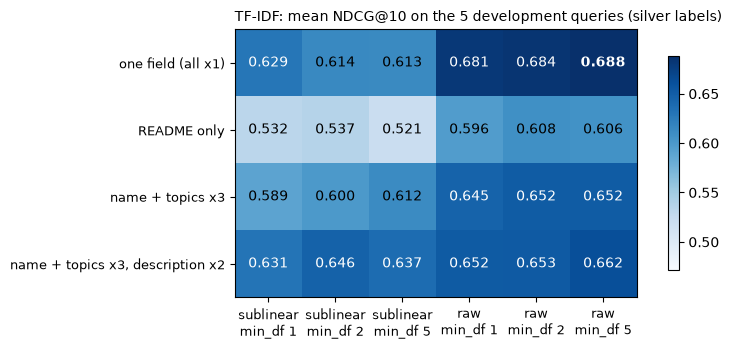

spread over the grid: 0.521 to 0.688 | step 6 setting (one field, sublinear, min_df 1): 0.629


,field weights,tf,min_df,new vs step 6,beginner inventory manag,point of sale app with r,school management system,hotel booking system spr,simple chat application,mean NDCG@10
0,one field (all x1),raw,5,4.4,0.527,0.397,0.958,0.766,0.792,0.688
1,one field (all x1),raw,2,4.2,0.527,0.397,0.958,0.745,0.792,0.684
2,one field (all x1),raw,1,3.4,0.464,0.385,0.956,0.745,0.855,0.681
3,"name + topics x3, description x2",raw,5,5.2,0.475,0.429,1.000,0.668,0.737,0.662
4,"name + topics x3, description x2",raw,2,5.2,0.475,0.429,0.958,0.668,0.735,0.653
5,"name + topics x3, description x2",raw,1,5.4,0.517,0.429,0.956,0.668,0.689,0.652
6,name + topics x3,raw,2,5.4,0.413,0.469,1.000,0.646,0.730,0.652
7,name + topics x3,raw,5,5.4,0.413,0.469,1.000,0.646,0.730,0.652
8,"name + topics x3, description x2",sublinear,2,2.0,0.461,0.524,0.867,0.594,0.783,0.646
9,name + topics x3,raw,1,5.2,0.476,0.426,0.958,0.646,0.721,0.645


In [7]:
# There are no labels yet (Phase 13), so this grid uses SILVER labels: a stand-in, not the final number.
# Same rule as 09-bm25 (and 10-1-semantic), so the numbers compare across methods. Each development query
# matches one collection slice (domain | framework) from Phase 2:
#   grade 2 = the repository was collected for that exact slice, grade 1 = same domain, other framework.
# Silver labels come from GitHub's own keyword search, so they favour word matching and miss relevant
# repositories outside the slice. Re-run this cell with the real development labels when they exist.
SLICE = dict(zip(DEV, [("inventory management", "nestjs"), ("point of sale", "react"), ("school management", "laravel"),
                       ("booking system", "spring-boot"), ("chat application", "flutter")]))

def silver(q):
    dom, fw = SLICE[q]
    g = {}
    for name, sel in zip(ids, corpus["selected_by"]):
        if f"{dom}|{fw}" in sel:
            g[name] = 2
        elif any(s.startswith(dom + "|") for s in sel):
            g[name] = 1
    return g

def ndcg10(ranked, grades):
    gain = [grades.get(d, 0) for d in ranked[:10]]
    dcg = sum((2**g - 1) / np.log2(r + 2) for r, g in enumerate(gain))
    ideal = sorted(grades.values(), reverse=True)[:10]
    return dcg / sum((2**g - 1) / np.log2(r + 2) for r, g in enumerate(ideal))

QRELS = {q: silver(q) for q in DEV}
print({q[:30]: f"{sum(v == 2 for v in g.values())} x2, {sum(v == 1 for v in g.values())} x1" for q, g in QRELS.items()})

FW = {"one field (all x1)": None,
      "README only": {"name": 0, "description": 0, "topics": 0},
      "name + topics x3": {"name": 3, "topics": 3},
      "name + topics x3, description x2": {"name": 3, "topics": 3, "description": 2}}
TF_MIN = [(sub, mdf) for sub in (True, False) for mdf in (1, 2, 5)]
default_top = {q: [h["doc_id"] for h in method.search(q)] for q in DEV}

t = time.perf_counter()
rows, runs = [], {}
for fw_name, fw in FW.items():
    for sub, mdf in TF_MIN:
        m = TfidfRanker(sublinear_tf=sub, min_df=mdf, field_weights=fw).fit(corpus, tokens=fields)
        ranked = {q: [h["doc_id"] for h in m.search(q)] for q in DEV}
        runs[(fw_name, sub, mdf)] = ranked
        per_q = [ndcg10(ranked[q], QRELS[q]) for q in DEV]
        rows.append({"field weights": fw_name, "tf": "sublinear" if sub else "raw", "min_df": mdf,
                     "new vs step 6": np.mean([len(set(ranked[q]) - set(default_top[q])) for q in DEV]),
                     **{q[:24]: v for q, v in zip(DEV, per_q)}, "mean NDCG@10": np.mean(per_q)})
grid = pd.DataFrame(rows)
print(f"{len(grid)} settings in {time.perf_counter() - t:.0f} s")

H = grid["mean NDCG@10"].to_numpy().reshape(len(FW), len(TF_MIN))
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(H, cmap="Blues", vmin=H.min() - .05, vmax=H.max())
ax.set_xticks(range(len(TF_MIN)), [f"{'sublinear' if s else 'raw'}\nmin_df {m}" for s, m in TF_MIN], fontsize=9)
ax.set_yticks(range(len(FW)), list(FW), fontsize=9)
best = np.unravel_index(np.argmax(H), H.shape)
for (r, c_), v in np.ndenumerate(H):
    ax.text(c_, r, f"{v:.3f}", ha="center", va="center", fontsize=10,
            color="white" if v > H.mean() else "black", fontweight="bold" if (r, c_) == best else None)
ax.set_title("TF-IDF: mean NDCG@10 on the 5 development queries (silver labels)", fontsize=10, loc="left")
fig.colorbar(im, ax=ax, shrink=.8); plt.tight_layout(); plt.show()

print(f"spread over the grid: {H.min():.3f} to {H.max():.3f} | step 6 setting (one field, sublinear, min_df 1): {H[0, 0]:.3f}")
grid.sort_values("mean NDCG@10", ascending=False).round(3).reset_index(drop=True)

In [8]:
# Why raw tf wins. Cosine divides each repository's score by the length of its whole vector. With sublinear tf
# every distinct word adds at least its idf to that length, so a long README is pushed down whatever it is about,
# and tiny repositories (a name and one line) win. With raw tf the length is dominated by the few most repeated
# words: a long README about a hotel booking app keeps "hotel" and "booking" among them.
row = {d: i for i, d in enumerate(ids)}
lens = pd.DataFrame({tf_: [np.median([dl[row[d]] for d in runs[("one field (all x1)", sub, 1)][q]]) for q in DEV]
                     for tf_, sub in [("sublinear", True), ("raw", False)]}, index=[q[:40] for q in DEV])
print(f"median tokens of the top 10, min_df 1, one field (corpus median: {np.median(dl):.0f})")
print(lens.to_string())

method = TfidfRanker().fit(corpus, tokens=fields)        # the class default is now the chosen setting
print("\nchosen:", method.params())
show_top(method, corpus, DEV)

median tokens of the top 10, min_df 1, one field (corpus median: 361)
                                          sublinear    raw
beginner inventory management system nes       15.0   21.5
point of sale app with react                   23.0   53.5
school management system laravel               18.0   18.5
hotel booking system spring boot               58.5  227.0
simple chat application flutter firebase       34.5  101.5



chosen: {'tf': 'raw', 'idf': 'smooth', 'min_df': 1, 'field_weights': {'name': 1, 'description': 1, 'topics': 1, 'readme': 1}}

# beginner inventory management system nestjs postgresql   (10 hits)
    0.540  jmw5598/inventory-management-system          ★15     Inventory management system using Angular 9, Ngrx, NestJS, T
    0.447  NadirBakhsh/nestjs-learn-zero-to-hero        ★19     NestJS Zero to Hero: Master NestJS with Comprehensive Tutori
    0.387  samisams1/Inventory-Management-React-Nest-Gr ★13     Inventory Management System with React, TypeScript, NestJS, 
    0.373  legionscript/inventory_management            ★34     Inventory Management project tutorial written with Python an
    0.351  guruminion777/React-Inventory-Management-Sys ★9      not specified
    0.341  mhmamun6316/inventory_management_system      ★6      Inventory Management System with Point of Sale(POS) using La
    0.338  jvoyugi/inventory                            ★12     An inventory management system using

**Tuning result (silver labels, 5 queries)**

- **tf is what matters.** Raw tf beats sublinear tf in every row and at every min_df: 0.681 vs 0.629 with one field and min_df 1. Per query it is better on *school* (0.867 → 0.956), *hotel* (0.576 → 0.745) and *chat* (0.702 → 0.855), the same on *inventory* (0.468 → 0.464) and worse on *point of sale* (0.532 → 0.385).
- **Why:** cosine divides by the length of the whole vector. With sublinear tf every distinct word adds at least its idf to that length, so any long README is pushed down and near-empty repositories win (step 6). With raw tf the length is dominated by the most repeated words, so a long README that is *about* the query keeps a large share. The top 10 gets longer (median 19–227 tokens vs 15–59, cell above) and reads better: for *chat*, all 10 are Flutter chat projects, against 4 non-chat projects with sublinear tf.
- **What raw tf costs:** repetition counts in full again, so a long README that repeats one query word can get in: `gqfjob/awesome-react-cn` (#10 for *point of sale*, *react* 523 times) is a link list, and `square/point-of-sale-android-sdk` is an SDK, not an app. That is why *point of sale* got worse.
- **Field weights do not help.** With raw tf, name + topics ×3 (with or without description ×2) is below one field in every column (0.645–0.662 vs 0.681–0.688). With sublinear tf, adding description ×2 helps a little (up to 0.646), still well below raw tf with one field. README only is the worst row (0.52–0.61): the name, description and topics carry the most precise words.
- **min_df barely matters** (at most 0.023 within a row). min_df 5 shrinks the vocabulary from 148,623 to 26,086 words, but a word a user types that is in fewer than 5 repositories (a rare library) would then be ignored.
- **Decision:** `TfidfRanker()` now defaults to **raw tf, smooth idf, min_df 1, one field** (0.681). Raw tf with min_df 5 is 0.688, within noise, and drops rare query words, so min_df stays 1. Re-run this cell with the real development labels (Phase 13); if sublinear tf wins there, it is one argument: `TfidfRanker(sublinear_tf=True)`.

## 8. Speed, results file, hand in

`measure()` times the build and the queries; `save_results()` writes `eval/results/tfidf.json` in the format the Results sheet imports. The metrics stay empty until Phase 13–14: then Member 6's `evaluate_method(method, split="test")` fills them in and you import the file in the **Results sheet** tab of the team plan, add your observations and download the PDF.

**Check:** `eval/results/tfidf.json` exists; this notebook is committed with its outputs on `dev-tfidf`; `pytest` passes.

In [9]:
speed = measure(lambda: TfidfRanker().fit(corpus), DEV)     # build includes tokenizing the corpus
print(speed)
out = save_results(method, speed)                          # method = the setting chosen in step 7
print(out.relative_to(PATHS["eval"].parent), "|", method.params())

{'build_s': 10.97, 'query_ms_median': 0.51, 'index_mb': 35.1}
eval\results\tfidf.json | {'tf': 'raw', 'idf': 'smooth', 'min_df': 1, 'field_weights': {'name': 1, 'description': 1, 'topics': 1, 'readme': 1}}


## Extra (optional): Why cosine and not dot product?

Rank once without the length scaling (plain dot product). Which repositories rise to the top, and how long are their READMEs? It is a good paragraph for the report on document length.

In [10]:
# Plain dot product: the same tf-idf weights, without dividing each repository by its length.
# (The query's length is the same for every repository, so it does not change the order.)
row = {d: i for i, d in enumerate(ids)}

def dot_search(m, Xd, q, k=10):
    cols_, qv = m.query_vector(q)
    s = Xd[:, cols_] @ qv
    hit = np.flatnonzero(s > 0)
    return [ids[i] for i in hit[np.lexsort((hit, -s[hit]))][:k]]

rows = []
for m in [TfidfRanker(sublinear_tf=True).fit(corpus, tokens=fields), method]:   # steps 2-6, and the chosen raw tf
    Xd = (sparse.diags(m.norms) @ m.X).tocsc()                                  # undo the length division
    for q in DEV:
        cos, dot = [h["doc_id"] for h in m.search(q)], dot_search(m, Xd, q)
        rows.append({"tf": m.params()["tf"], "query": q[:32], "same in top 10": len(set(cos) & set(dot)),
                     "cosine: median tokens": np.median([dl[row[d]] for d in cos]),
                     "dot: median tokens": np.median([dl[row[d]] for d in dot]),
                     "cosine NDCG@10": ndcg10(cos, QRELS[q]), "dot NDCG@10": ndcg10(dot, QRELS[q])})
cmp = pd.DataFrame(rows)
print(f"corpus: median {np.median(dl):.0f} tokens, 90th percentile {np.percentile(dl, 90):.0f}\n")
print(cmp.round(3).to_string(index=False))
print("\nmean over the 5 queries:")
print(cmp.groupby("tf", sort=False).mean(numeric_only=True).round(3).to_string())

print(f"\ntop 5 by plain dot product, raw tf, for: {DEV[1]}")
for d in dot_search(method, Xd, DEV[1], 5):
    print(f"  {d[:44]:44s} {dl[row[d]]:6,} tokens, 'react' {Counter(docs[row[d]])['react']:3d} times  "
          f"{str(corpus.description.iloc[row[d]])[:45]}")

corpus: median 361 tokens, 90th percentile 2056

       tf                            query  same in top 10  cosine: median tokens  dot: median tokens  cosine NDCG@10  dot NDCG@10
sublinear beginner inventory management sy               0                   15.0              2180.0           0.468        0.423
sublinear     point of sale app with react               0                   23.0              1484.0           0.532        0.609
sublinear school management system laravel               0                   18.0               710.0           0.867        1.000
sublinear hotel booking system spring boot               2                   58.5               445.0           0.576        0.782
sublinear simple chat application flutter                0                   34.5              1533.0           0.702        0.574
      raw beginner inventory management sy               0                   21.5              2215.5           0.464        0.022
      raw     point of sale app wi

**Cosine vs dot product**
- Dividing by the length changes almost the whole top 10 (on average less than one repository in common). Without it, the top 10 are the longest READMEs: a median of 1,270 tokens with sublinear tf and 1,950 with raw tf (averaged over the 5 queries), against 361 for the corpus and 2,056 for its 90th percentile, so READMEs near the 20,000-character cap.
- With raw tf the dot product is useless (silver NDCG@10 0.12): a README that says *react* 165 to 523 times wins, so the top 5 for *point of sale app with react* are awesome-lists and link collections. With sublinear tf the log damps repetition, and on these labels the dot product even does a little better than cosine (0.678 vs 0.629).
- So cosine over-corrects for length (near-empty repositories win, step 6) and the dot product does not correct at all (link lists win). The right amount is in between. That is BM25's `b` (a partial length correction, with a tf that saturates), and the main reason BM25 beats TF-IDF here.

## What we found

- **Speed:** builds in about 11 s for 8,223 repositories (tokenizing is ~10 s of that; the class builds the matrix in 1–2 s), answers a query in 0.5 ms (median), index 35 MB (one sparse matrix: 148,623 words, 2.5 M non-zero weights). No GPU, nothing to download.
- **Correct:** the same matrix as scikit-learn's `TfidfVectorizer` (largest difference 8e-16), the same top 10 in the same order on all 5 queries, and the hand calculation for one repository matches the code (0.5177). `tests/test_tfidf.py` checks the same on a small corpus (raw and sublinear tf, min_df 1 and 2), plus the cosine by hand, field weights = repeating the field, and the edge cases.
- **Setting:** raw tf, smooth idf, min_df 1, one field (name + description + topics + README): 0.681 mean silver NDCG@10, against 0.629 for the starter code's sublinear tf. Field weights and min_df do not help. To confirm on the real development labels.
- **Good:** precise when the query words are what the repository calls itself: Laravel school management systems, Flutter + Firebase chat projects (10 of 10 with raw tf).
- **Bad:** (1) cosine favours near-empty repositories: a 10-token repository with *nestjs* twice and no inventory word is still in the inventory top 10 (#9 with raw tf, #3 with sublinear); (2) right stack, wrong project: a NestJS course (#2) and a NestJS + PostgreSQL hospital system (#10) for the inventory query, a Spring Boot library system for hotel booking; (3) with raw tf, long link lists that repeat one word (awesome-react) can get in. Synonyms are missed entirely: a "stock tracker" never matches "inventory" (semantic search, 10.1).
- **Compared with BM25 (H1):** 0.681 vs 0.801 for BM25 at its default k1 = 1.5, b = 0.75, on the same 5 queries and silver labels (`09-bm25` on `dev-bm25`). BM25 wins, as expected: its `b` corrects for length partly, where cosine over-corrects (Extra). The real comparison comes in Phase 14.
- `eval/results/tfidf.json` is written (params + speed); the metrics fill in after Phase 14 (`evaluate_method`).